**Live Deployment Link:** [https://YOUR-APP-NAME.streamlit.app/](https://YOUR-APP-NAME.streamlit.app/)  *(placeholder: replace with your real Streamlit Community Cloud URL after deploying, see Step 10)*

---

# Heart Disease Prediction System
### An End-to-End Machine Learning System: Binary Classification on Structured Data

| Item | Details |
|---|---|
| **Student** | Haziq Mahmood |
| **Roll Number** | FA24-BSE-049 |
| **Course** | AIC354 - Machine Learning Fundamentals (BS-CS) |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |
| **Assignment** | Assignment 2, Task 2: Heart Disease Prediction System |
| **Institution** | COMSATS University Islamabad, Lahore Campus (Fall 2026) |

## Project Overview

**Problem.** Given four measurements from a cardiac check-up and exercise stress test, predict whether a patient has heart disease.

**System specification**

| | Description |
|---|---|
| **Input (I)** | **4 numeric attributes**: `cp`, `thalach`, `oldpeak`, `exang`, chosen from the 13 available attributes (selection justified in Step 4.3) |
| **Output (O)** | **1 attribute**: `target` with values **0 or 1** (0 = no heart disease, 1 = heart disease present) |
| **Task type** | Supervised learning, binary classification on structured (tabular) data |
| **Model** | Support Vector Classifier (SVC) inside a scikit-learn `Pipeline` with feature scaling |
| **Dataset** | UCI Heart Disease, Cleveland Clinic Foundation subset: 303 patients ([source](https://archive.ics.uci.edu/dataset/45/heart+disease)) |
| **Deployment** | Streamlit web app on Streamlit Community Cloud |

**Machine Learning cycle followed in this notebook.** The notebook follows the instructor's teaching structure: *Import Libraries, Load Data, Preprocess, Encode, Train, Test, Deploy, Collect Feedback*, grouped into the four phases of the ML cycle:

| Phase | Notebook steps |
|---|---|
| **1. Data**: collection, understanding, preprocessing | Step 2 Load Data, Step 3 Data Understanding, Step 4 Preprocessing, Step 5 Encoding check |
| **2. Model training** | Step 6 Train the Model |
| **3. Model testing and evaluation** | Step 7 Test the Model |
| **4. Deployment and feedback** | Step 8 Save Model, Step 9 Predict, Step 10 Deploy, Step 11 Collect Feedback |

**What was modified compared with the Titanic notebook**

1. New dataset and a new set of **4 input attributes**.
2. The original diagnosis attribute `num` (0 to 4) is converted into a **binary output (0/1)**.
3. **The label-encoding code is removed.** Every heart-disease attribute is already numeric, so there is nothing to encode (Step 5 verifies this in code).
4. The **range of values** of each input is documented (Step 4.5) and enforced when predicting (Step 9) and in the web app.
5. Evaluation goes beyond accuracy (precision, recall, F1, ROC-AUC, confusion matrix), because accuracy alone can hide dangerous errors in a medical setting.

## How to Run This Notebook

Keep these files in the same folder: `Heart_Disease_Prediction.ipynb`, `processed_cleveland.csv`, `app.py`, `requirements.txt`, `requirements-notebook.txt`.

```
python -m venv venv
venv\Scripts\activate            # Windows   (macOS/Linux: source venv/bin/activate)
pip install -r requirements-notebook.txt
jupyter notebook
```

Open the notebook and choose **Kernel > Restart & Run All**. Running it creates `heart_disease_model.pkl` and `model_info.json` in the same folder. All random operations use a fixed seed (`RANDOM_STATE = 42`), so results are reproducible.

---
# Step 1: Import Libraries

In [1]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, GridSearchCV, cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", None)   # never cut off long text in tables

RANDOM_STATE = 42   # fixed seed, so every run gives identical results
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


---
# Step 2: Load Data (Data Collection)

The data comes from the UCI Machine Learning Repository, **Heart Disease** dataset. UCI provides four hospital databases; this project uses the **Cleveland Clinic Foundation** file (`processed.cleveland.data`, saved here as `processed_cleveland.csv` with a header row added; the data rows are unchanged).

Why Cleveland? The UCI documentation notes that it is the only database used by ML researchers so far, and it is the most complete: at the other three sites, the attribute `ca` is missing for 96% to 99% of patients and several other attributes have large gaps.

In the raw UCI file, missing values are written as `?`, so `na_values="?"` is used to turn them into proper missing values (`NaN`).

**Data dictionary** (14 attributes, all numeric)

| Attribute | Meaning | Values / unit |
|---|---|---|
| `age` | Age of the patient | years |
| `sex` | Sex | 1 = male, 0 = female |
| `cp` | Chest pain type | 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic |
| `trestbps` | Resting blood pressure on admission | mm Hg |
| `chol` | Serum cholesterol | mg/dl |
| `fbs` | Fasting blood sugar > 120 mg/dl | 1 = true, 0 = false |
| `restecg` | Resting electrocardiographic result | 0 = normal, 1 = ST-T wave abnormality, 2 = probable/definite left ventricular hypertrophy |
| `thalach` | Maximum heart rate achieved during the stress test | beats per minute |
| `exang` | Exercise-induced angina | 1 = yes, 0 = no |
| `oldpeak` | ST depression induced by exercise relative to rest | numeric (mm) |
| `slope` | Slope of the peak exercise ST segment | 1 = upsloping, 2 = flat, 3 = downsloping |
| `ca` | Number of major vessels (0 to 3) coloured by fluoroscopy | count |
| `thal` | Thallium stress-test result | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| `num` | **Diagnosis of heart disease** (angiographic disease status) | 0 = no disease (< 50% narrowing), 1 to 4 = disease present |

In [2]:
DATA_PATH = Path("processed_cleveland.csv")
df = pd.read_csv(DATA_PATH, na_values="?")   # '?' marks a missing value in the UCI file

print("Shape (rows, columns):", df.shape)
df.head(10)

Shape (rows, columns): (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


---
# Step 3: Data Understanding (Exploratory Data Analysis)

## 3.1 Structure and data types

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


## 3.2 Summary statistics

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 3.3 Data quality: missing values, duplicates, and valid category codes

In [5]:
missing = df.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0].to_string())
print("\nTotal rows containing a missing value:", int(df.isna().any(axis=1).sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

print("\nValues found in the category-coded columns:")
for col in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    print(f"  {col:8s} -> {sorted(int(v) for v in df[col].dropna().unique())}")

Columns with missing values:
ca      4
thal    2

Total rows containing a missing value: 6
Duplicate rows: 0

Values found in the category-coded columns:
  sex      -> [0, 1]
  cp       -> [1, 2, 3, 4]
  fbs      -> [0, 1]
  restecg  -> [0, 1, 2]
  exang    -> [0, 1]
  slope    -> [1, 2, 3]
  ca       -> [0, 1, 2, 3]
  thal     -> [3, 6, 7]


**Observations**

- 303 patients and 13 input attributes plus the diagnosis `num`. Every column is already numeric.
- Only `ca` (4 values) and `thal` (2 values) have missing entries. None of the other 11 attributes has any.
- There are no duplicate rows.
- The category-coded columns contain exactly the codes listed in the data dictionary, so there are no invalid codes.

## 3.4 The target attribute `num`

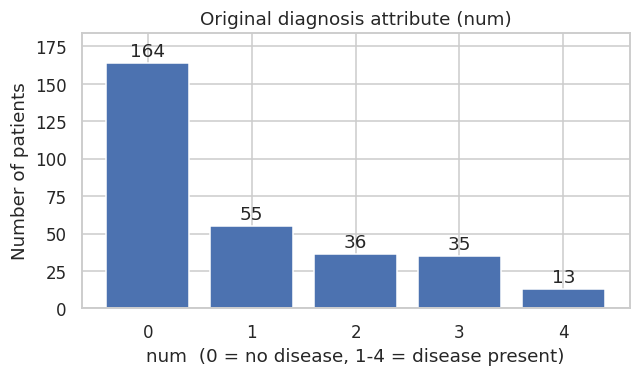

In [6]:
counts = df["num"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
ax.bar_label(bars, padding=2)
ax.margins(y=0.12)
ax.set(title="Original diagnosis attribute (num)", xlabel="num  (0 = no disease, 1-4 = disease present)",
       ylabel="Number of patients")
plt.tight_layout()
plt.show()

`num` has five values (0 to 4). The UCI documentation states that experiments on the Cleveland data concentrate on the simpler question of **presence (values 1 to 4) versus absence (value 0)** of heart disease. That is exactly the 1-output-attribute, 0/1 system required here, so `num` will be converted to a binary target in Step 4.1.

---
# Step 4: Data Preprocessing

## 4.1 Create the binary output attribute (0/1)

The output of the system is a single attribute with values **0 or 1**:

- `target = 0` : no heart disease (`num == 0`)
- `target = 1` : heart disease present (`num` is 1, 2, 3 or 4)

This is a *target conversion*, not label encoding: no text categories are involved.

                     patients  percent
target                                
0 = no disease            164     54.1
1 = disease present       139     45.9


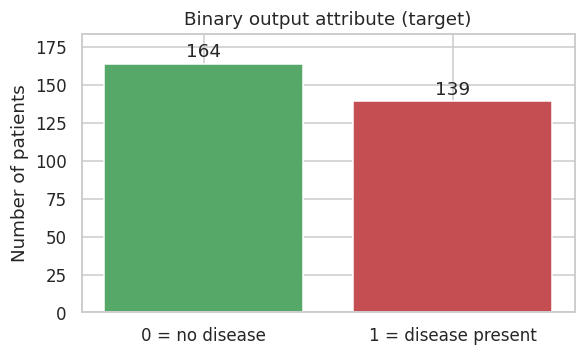

A model that always predicts the majority class would score 54.1% accuracy.


In [7]:
df["target"] = (df["num"] > 0).astype(int)

class_counts = df["target"].value_counts().sort_index()
class_pct = (class_counts / len(df) * 100).round(1)
print(pd.DataFrame({"patients": class_counts, "percent": class_pct}).rename(
    index={0: "0 = no disease", 1: "1 = disease present"}))

fig, ax = plt.subplots(figsize=(5.5, 3.4))
bars = ax.bar(["0 = no disease", "1 = disease present"], class_counts.values, color=["#55A868", "#C44E52"])
ax.bar_label(bars, padding=2)
ax.margins(y=0.12)
ax.set(title="Binary output attribute (target)", ylabel="Number of patients")
plt.tight_layout()
plt.show()

print(f"A model that always predicts the majority class would score {class_counts.max() / len(df):.1%} accuracy.")

The classes are fairly balanced (54% / 46%), so no resampling is needed and accuracy is a meaningful metric. The always-predict-majority score of about 54% is the **baseline every real model must beat**.

## 4.2 Split into training and test sets

The data is split **before** any feature selection or model fitting, so the test patients play no role in any decision. The split is stratified, which keeps the same 0/1 proportion in both parts, and the test set stays untouched until Step 7.

In [8]:
FEATURE_CANDIDATES = [c for c in df.columns if c not in ("num", "target")]   # the 13 original inputs

train_df, test_df = train_test_split(
    df, test_size=0.20, stratify=df["target"], random_state=RANDOM_STATE)

print(f"Training patients: {len(train_df)}  (disease rate {train_df['target'].mean():.1%})")
print(f"Test patients    : {len(test_df)}  (disease rate {test_df['target'].mean():.1%})")

Training patients: 242  (disease rate 45.9%)
Test patients    : 61  (disease rate 45.9%)


## 4.3 Select the 4 input attributes

The system must use **exactly 4 of the 13 attributes**. The ranking below uses the **training set only** and measures how strongly each attribute is associated with the target, using absolute Pearson correlation and mutual information (which also captures non-linear relationships).

**Selection rules**

1. **Complete attributes only.** No missing values, so no imputation is needed and every future user can supply the value.
2. **Strongest association** with the target by both measures.
3. **Practical.** The inputs should come from a standard exercise stress test and be easy to enter in a web form.

In [9]:
X_cand = train_df[FEATURE_CANDIDATES]
ranking = pd.DataFrame({
    "missing_values": X_cand.isna().sum(),
    "abs_correlation": X_cand.corrwith(train_df["target"]).abs(),
    "mutual_information": mutual_info_classif(
        X_cand.fillna(X_cand.median()), train_df["target"],
        discrete_features=False, random_state=RANDOM_STATE),
}).sort_values("abs_correlation", ascending=False)

display(ranking.round(3))

complete = ranking[ranking["missing_values"] == 0]
top4_complete = complete.head(4).index.tolist()
print("Top 4 complete attributes by absolute correlation:", top4_complete)

,missing_values,abs_correlation,mutual_information
thal,1,0.550,0.183
ca,1,0.453,0.150
exang,0,0.420,0.066
thalach,0,0.409,0.091
cp,0,0.401,0.134
oldpeak,0,0.392,0.079
slope,0,0.323,0.104
sex,0,0.308,0.024
age,0,0.210,0.000
restecg,0,0.160,0.005


Top 4 complete attributes by absolute correlation: ['exang', 'thalach', 'cp', 'oldpeak']


Selected inputs match the top-4 complete attributes: True


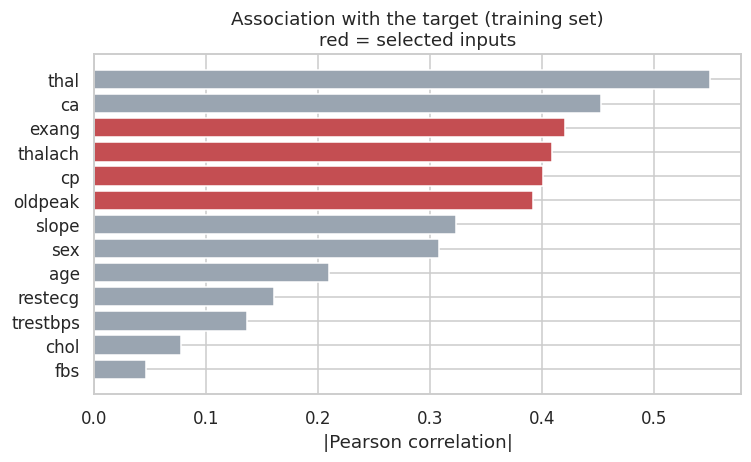

In [10]:
SELECTED_FEATURES = ["cp", "thalach", "oldpeak", "exang"]
print("Selected inputs match the top-4 complete attributes:", set(SELECTED_FEATURES) == set(top4_complete))

order = ranking.sort_values("abs_correlation")
colors = ["#C44E52" if f in SELECTED_FEATURES else "#9AA5B1" for f in order.index]

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.barh(order.index, order["abs_correlation"], color=colors)
ax.set(title="Association with the target (training set)\nred = selected inputs", xlabel="|Pearson correlation|")
plt.tight_layout()
plt.show()

**Selected inputs**

| Attribute | Why it was chosen |
|---|---|
| `cp` (chest pain type) | Highest mutual information among the attributes with no missing values; patients with *asymptomatic* chest pain (type 4) show a much higher disease rate |
| `thalach` (maximum heart rate achieved) | Strong negative association: a lower peak heart rate goes with a higher disease rate |
| `oldpeak` (ST depression) | Strong positive association with the target |
| `exang` (exercise-induced angina) | Strong positive association with the target |

`ca` and `thal` correlate even more strongly, but they were deliberately **not** chosen: they contain missing values, and `thal` comes from a thallium imaging test that a typical user would not know.

**Sanity check.** Is this choice competitive with other 4-attribute subsets? Each subset below is scored with an untuned SVC and 5-fold cross-validation repeated 5 times, using the **training set only**.

In [11]:
CV_REPEATED = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
base_pipeline = Pipeline([("scaler", StandardScaler()), ("model", SVC())])

subsets = {
    "cp, thalach, oldpeak, exang   (SELECTED)": ["cp", "thalach", "oldpeak", "exang"],
    "sex, cp, thalach, oldpeak": ["sex", "cp", "thalach", "oldpeak"],
    "age, sex, cp, oldpeak": ["age", "sex", "cp", "oldpeak"],
    "age, sex, cp, trestbps": ["age", "sex", "cp", "trestbps"],
    "age, trestbps, chol, fbs   (basic check-up values)": ["age", "trestbps", "chol", "fbs"],
}

rows = []
for name, cols in subsets.items():
    scores = cross_val_score(base_pipeline, train_df[cols], train_df["target"],
                             cv=CV_REPEATED, scoring="accuracy")
    rows.append({"Input attributes": name, "CV accuracy (mean)": scores.mean(), "Std": scores.std()})

subset_table = pd.DataFrame(rows).sort_values("CV accuracy (mean)", ascending=False).reset_index(drop=True)
display(subset_table.round(3))

,Input attributes,CV accuracy (mean),Std
0,"age, sex, cp, oldpeak",0.772,0.051
1,"sex, cp, thalach, oldpeak",0.762,0.055
2,"cp, thalach, oldpeak, exang (SELECTED)",0.761,0.049
3,"age, sex, cp, trestbps",0.760,0.052
4,"age, trestbps, chol, fbs (basic check-up values)",0.574,0.057


The selected subset performs on par with the best alternatives; the differences among the top subsets are smaller than the fold-to-fold variation (the `Std` column), so chasing a tiny gain would just be fitting noise. The weakest subset is the one made of basic check-up values (age, resting blood pressure, cholesterol, fasting blood sugar): at about 57% it is barely above the 54% majority-class baseline. This shows that **chest pain type and exercise stress-test results carry far more signal** than blood pressure or cholesterol in this dataset.

## 4.4 Build the input matrix (X) and output vector (y)

In [12]:
X_train = train_df[SELECTED_FEATURES].copy()
y_train = train_df["target"].copy()
X_test = test_df[SELECTED_FEATURES].copy()
y_test = test_df["target"].copy()

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)
X_train.head()

X_train: (242, 4) | y_train: (242,)
X_test : (61, 4) | y_test : (61,)


,cp,thalach,oldpeak,exang
180,4.0,166.0,0.5,0.0
208,2.0,155.0,0.0,0.0
167,2.0,159.0,0.0,1.0
105,2.0,156.0,0.0,0.0
297,4.0,123.0,0.2,1.0


**How do the four inputs relate to the output?** (training set)

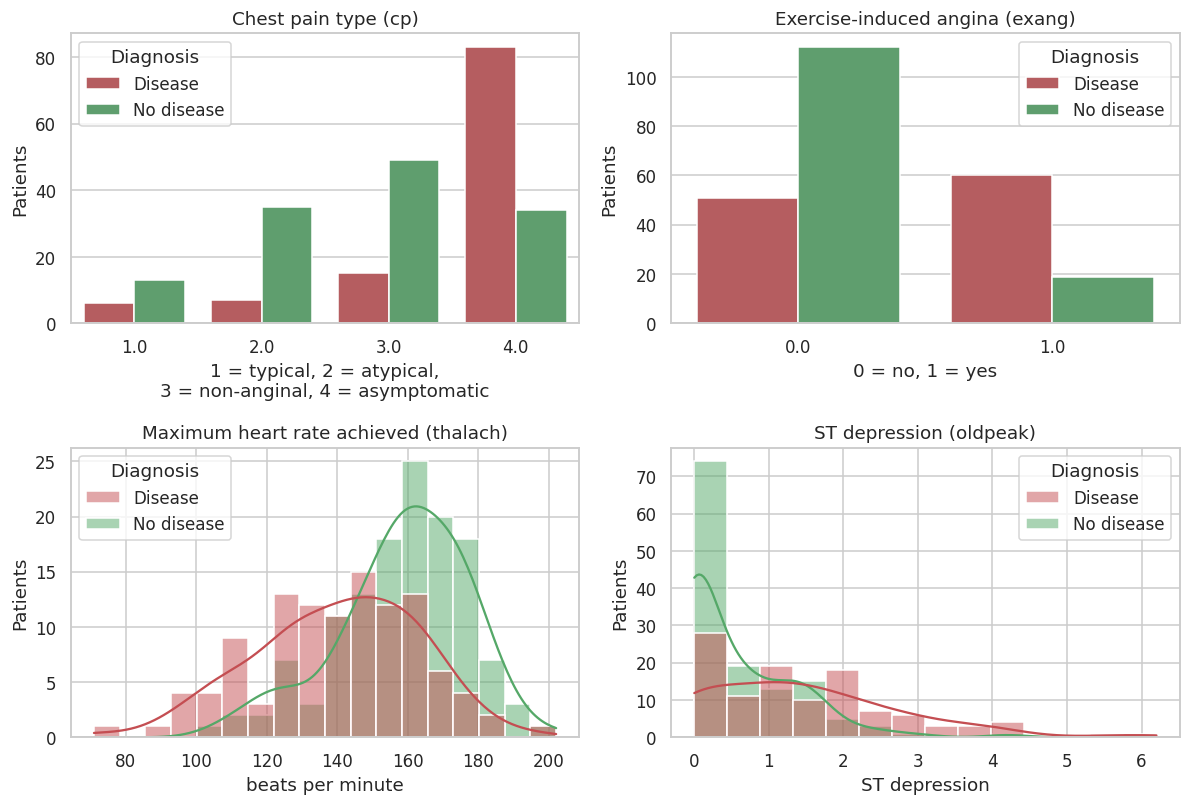

Disease rate by chest pain type (training set):
     patients  disease_rate
cp                         
1.0        19         0.316
2.0        42         0.167
3.0        64         0.234
4.0       117         0.709


In [13]:
LABELS = {0: "No disease", 1: "Disease"}
PALETTE = {"No disease": "#55A868", "Disease": "#C44E52"}
plot_df = X_train.assign(Diagnosis=y_train.map(LABELS))

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

sns.countplot(data=plot_df, x="cp", hue="Diagnosis", palette=PALETTE, ax=axes[0, 0])
axes[0, 0].set(title="Chest pain type (cp)", xlabel="1 = typical, 2 = atypical,\n3 = non-anginal, 4 = asymptomatic",
               ylabel="Patients")

sns.countplot(data=plot_df, x="exang", hue="Diagnosis", palette=PALETTE, ax=axes[0, 1])
axes[0, 1].set(title="Exercise-induced angina (exang)", xlabel="0 = no, 1 = yes", ylabel="Patients")

sns.histplot(data=plot_df, x="thalach", hue="Diagnosis", palette=PALETTE, bins=18, kde=True, ax=axes[1, 0])
axes[1, 0].set(title="Maximum heart rate achieved (thalach)", xlabel="beats per minute", ylabel="Patients")

sns.histplot(data=plot_df, x="oldpeak", hue="Diagnosis", palette=PALETTE, bins=14, kde=True, ax=axes[1, 1])
axes[1, 1].set(title="ST depression (oldpeak)", xlabel="ST depression", ylabel="Patients")

plt.tight_layout()
plt.show()

print("Disease rate by chest pain type (training set):")
print(train_df.groupby("cp")["target"].agg(patients="count", disease_rate="mean").round(3).to_string())

**Findings**

- **cp**: patients with type 4 (*asymptomatic*) chest pain are mostly disease-positive, while types 1 to 3 are mostly disease-negative. The relationship is **not monotonic** (type 1 is higher than types 2 and 3), which is one reason a non-linear model such as an RBF-kernel SVC is a good fit.
- **exang**: exercise-induced angina strongly shifts the odds toward disease.
- **thalach**: disease-positive patients reach a *lower* maximum heart rate.
- **oldpeak**: disease-positive patients show larger ST depression; the distribution is right-skewed with a long tail.

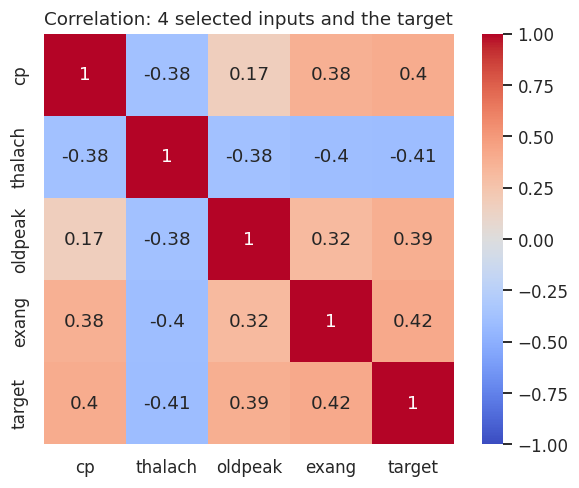

Largest correlation between two different inputs: 0.40


In [14]:
corr = train_df[SELECTED_FEATURES + ["target"]].corr().round(2)

fig, ax = plt.subplots(figsize=(5.8, 4.6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation: 4 selected inputs and the target")
plt.tight_layout()
plt.show()

input_corr = corr.loc[SELECTED_FEATURES, SELECTED_FEATURES].abs().to_numpy()
print(f"Largest correlation between two different inputs: {np.triu(input_corr, k=1).max():.2f}")

The inputs are only moderately correlated with one another (the largest value, printed above, is about 0.4), so each one adds its own information and there is no redundancy problem.

## 4.5 Missing values, outliers, and the range of values

**Missing values.** The four selected inputs must contain none, so no imputation is needed.

**Outliers.** Values outside the 1.5 x IQR fences are counted for the two continuous inputs. They are only **flagged, not removed**: extreme but clinically plausible readings (for example a high ST depression) are exactly the cases a disease detector must handle, and they are real measurements, not data-entry errors.

In [15]:
print("Missing values in the 4 selected inputs:", int(df[SELECTED_FEATURES].isna().sum().sum()))

outlier_rows = []
for col in ["thalach", "oldpeak"]:
    q1, q3 = train_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((train_df[col] < low) | (train_df[col] > high)).sum())
    outlier_rows.append({"attribute": col, "Q1": q1, "Q3": q3, "lower fence": round(low, 2),
                         "upper fence": round(high, 2), "outliers (training)": n_out})
display(pd.DataFrame(outlier_rows))

Missing values in the 4 selected inputs: 0


,attribute,Q1,Q3,lower fence,upper fence,outliers (training)
0,thalach,134.5,166.0,87.25,213.25,1
1,oldpeak,0.0,1.6,-2.40,4.00,4


**Range of values of the inputs and the output.** The valid range of every input is taken from the observed minimum and maximum over the dataset. The system **only accepts values inside these ranges**: the model was trained on patients in this range, and predictions outside it would be extrapolation and therefore unreliable. The range is enforced in the prediction function (Step 9) and in the web app (`app.py`).

In [16]:
INPUT_RANGES = {
    "cp":      (int(df["cp"].min()),      int(df["cp"].max())),
    "thalach": (int(df["thalach"].min()), int(df["thalach"].max())),
    "oldpeak": (float(df["oldpeak"].min()), float(df["oldpeak"].max())),
    "exang":   (int(df["exang"].min()),   int(df["exang"].max())),
}

input_spec = pd.DataFrame({
    "Attribute": ["cp", "thalach", "oldpeak", "exang"],
    "Meaning": ["Chest pain type", "Maximum heart rate achieved", "ST depression induced by exercise",
                "Exercise-induced angina"],
    "Type": ["categorical code", "integer (bpm)", "decimal", "binary"],
    "Range of values": [
        "1 to 4  (1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic)",
        f"{INPUT_RANGES['thalach'][0]} to {INPUT_RANGES['thalach'][1]} bpm",
        f"{INPUT_RANGES['oldpeak'][0]} to {INPUT_RANGES['oldpeak'][1]}",
        "0 or 1  (0 = no, 1 = yes)"],
})
print("INPUTS (I): 4 attributes")
display(input_spec)

print("OUTPUT (O): 1 attribute")
display(pd.DataFrame({"Attribute": ["target"], "Meaning": ["Heart disease diagnosis"],
                      "Range of values": ["0 = no heart disease, 1 = heart disease present"]}))

INPUTS (I): 4 attributes


,Attribute,Meaning,Type,Range of values
0,cp,Chest pain type,categorical code,"1 to 4 (1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic)"
1,thalach,Maximum heart rate achieved,integer (bpm),71 to 202 bpm
2,oldpeak,ST depression induced by exercise,decimal,0.0 to 6.2
3,exang,Exercise-induced angina,binary,"0 or 1 (0 = no, 1 = yes)"


OUTPUT (O): 1 attribute


,Attribute,Meaning,Range of values
0,target,Heart disease diagnosis,"0 = no heart disease, 1 = heart disease present"


---
# Step 5: Label Encoding Check

In the Titanic notebook, this step converted text columns (for example `Gender` and `Embarked`) into numbers. **That code has been removed here**, because the Heart Disease dataset has no text columns: every attribute, including the four selected inputs, is already numeric (`cp` and `exang` are numeric codes). Applying a label encoder would change nothing.

The check below confirms in code that nothing needs to be encoded.

In [17]:
non_numeric = X_train.select_dtypes(exclude="number").columns.tolist()
print("Input columns that still need encoding:", non_numeric)
assert not non_numeric, "Non-numeric input found, encoding would be required"
print("Data types of the inputs:")
print(X_train.dtypes.to_string())

Input columns that still need encoding: []
Data types of the inputs:
cp         float64
thalach    float64
oldpeak    float64
exang      float64


---
# Step 6: Train the Model

## 6.1 Compare candidate models (training set only)

The deployed model is a **Support Vector Classifier (SVC)**, the same model family as the Titanic system. Before committing to it, it is compared with a naive baseline and four other common classifiers. Every model is scored with 5-fold cross-validation repeated 5 times (25 scores per model) on the **training set only**.

Models that are sensitive to the scale of the inputs (SVC, Logistic Regression, k-NN) are wrapped in a `Pipeline` with `StandardScaler`. Scaling happens *inside* each cross-validation fold, so no information leaks from the validation fold.

,Model,CV accuracy (mean),Std
0,SVC (default settings),0.761,0.049
1,Logistic Regression,0.761,0.052
2,Random Forest (depth 4),0.745,0.052
3,k-Nearest Neighbours,0.733,0.053
4,Decision Tree (depth 4),0.706,0.054
5,Majority-class baseline,0.541,0.006


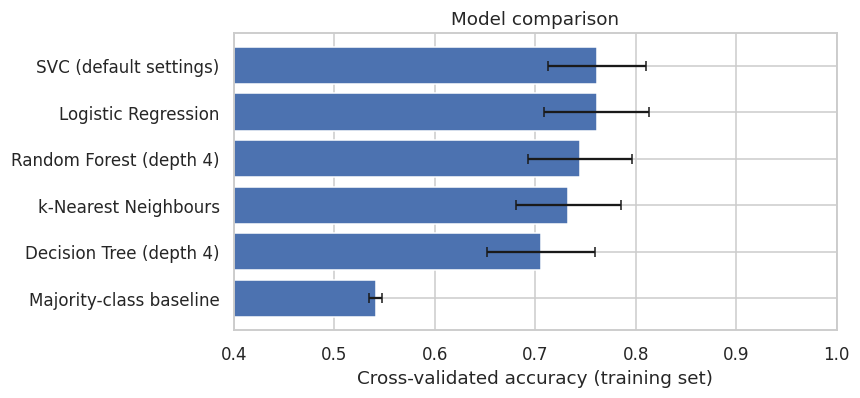

In [18]:
candidates = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "SVC (default settings)": Pipeline([("scaler", StandardScaler()), ("model", SVC())]),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]),
    "k-Nearest Neighbours": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())]),
    "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest (depth 4)": RandomForestClassifier(n_estimators=200, max_depth=4, random_state=RANDOM_STATE),
}

rows = []
for name, estimator in candidates.items():
    scores = cross_val_score(estimator, X_train, y_train, cv=CV_REPEATED, scoring="accuracy")
    rows.append({"Model": name, "CV accuracy (mean)": scores.mean(), "Std": scores.std()})

comparison = pd.DataFrame(rows).sort_values("CV accuracy (mean)", ascending=False).reset_index(drop=True)
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
plot_order = comparison.iloc[::-1]
ax.barh(plot_order["Model"], plot_order["CV accuracy (mean)"], xerr=plot_order["Std"],
        color="#4C72B0", capsize=3)
ax.set(xlim=(0.4, 1.0), xlabel="Cross-validated accuracy (training set)", title="Model comparison")
plt.tight_layout()
plt.show()

Every real model clearly beats the majority-class baseline. SVC and Logistic Regression are tied at the top, Random Forest and k-NN are within about one standard deviation of them, and the shallow Decision Tree is the weakest. **SVC is kept**: it is competitive, it matches the instructor's Titanic pipeline, and an RBF kernel can capture the non-monotonic effect of `cp`.

## 6.2 Tune the SVC hyperparameters

`GridSearchCV` tries every combination of the settings below with 5-fold stratified cross-validation on the training set and keeps the best one. The test set is **not** used here.

- `C`: regularisation strength (small = smoother boundary, large = fits training data more tightly)
- `gamma`: reach of a single training point in the RBF kernel (ignored by the linear kernel)
- `kernel`: `rbf` (non-linear) or `linear`

In [19]:
svc_pipeline = Pipeline([("scaler", StandardScaler()), ("model", SVC())])

param_grid = {
    "model__C": [0.1, 0.5, 1, 2, 5, 10],
    "model__gamma": ["scale", 0.01, 0.05, 0.1, 0.3, 1],
    "model__kernel": ["rbf", "linear"],
}

grid = GridSearchCV(
    svc_pipeline, param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="accuracy", refit=True)
grid.fit(X_train, y_train)

print("Best hyperparameters :", grid.best_params_)
print(f"Best CV accuracy     : {grid.best_score_:.3f}")
print(f"Combinations tried   : {len(grid.cv_results_['params'])}")

top = (pd.DataFrame(grid.cv_results_)
       .sort_values(["rank_test_score", "param_model__C"])
       [["param_model__kernel", "param_model__C", "param_model__gamma",
         "mean_test_score", "std_test_score", "rank_test_score"]]
       .rename(columns=lambda c: c.replace("param_model__", "")).head(6).round(3))
display(top.reset_index(drop=True))

Best hyperparameters : {'model__C': 0.5, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Best CV accuracy     : 0.777
Combinations tried   : 72


,kernel,C,gamma,mean_test_score,std_test_score,rank_test_score
0,rbf,0.5,0.01,0.777,0.040,1
1,rbf,0.1,0.05,0.773,0.039,2
2,rbf,0.1,0.1,0.773,0.039,2
3,rbf,10.0,0.05,0.769,0.036,4
4,rbf,5.0,0.05,0.769,0.034,5
5,rbf,1.0,0.1,0.769,0.031,6


## 6.3 Final model

`GridSearchCV` (with `refit=True`) has already re-trained the best configuration on **all 242 training patients**. That fitted pipeline (scaler + SVC) is the final model. Because the scaler is part of the pipeline, the saved model accepts raw input values.

In [20]:
model = grid.best_estimator_
print(model)
print(f"\nTraining accuracy: {accuracy_score(y_train, model.predict(X_train)):.3f}")
print("Number of support vectors per class:", model.named_steps["model"].n_support_.tolist())

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', SVC(C=0.5, gamma=0.01))])

Training accuracy: 0.777
Number of support vectors per class: [88, 89]


---
# Step 7: Test the Model

The model is now evaluated **once** on the 61 test patients it has never seen.

## 7.1 Performance metrics

In [21]:
y_pred = model.predict(X_test)
y_score = model.decision_function(X_test)      # signed distance from the SVM decision boundary

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
baseline_acc = max(y_test.mean(), 1 - y_test.mean())

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall (sensitivity)": recall_score(y_test, y_pred),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_score),
}
metrics_table = pd.DataFrame({"Test-set value": metrics}).round(3)
display(metrics_table)
print(f"Majority-class baseline accuracy on the same test set: {baseline_acc:.3f}")

,Test-set value
Accuracy,0.820
Precision,0.870
Recall (sensitivity),0.714
Specificity,0.909
F1-score,0.784
ROC-AUC,0.925


Majority-class baseline accuracy on the same test set: 0.541


**Reading the metrics**

- **Accuracy**: share of all patients classified correctly.
- **Precision**: of the patients flagged as *disease*, how many really have it.
- **Recall (sensitivity)**: of the patients who really have the disease, how many were caught. In a screening setting a missed patient (false negative) is usually the costlier mistake, so this is the metric to watch.
- **Specificity**: of the healthy patients, how many were correctly cleared.
- **F1-score**: harmonic mean of precision and recall.
- **ROC-AUC**: how well the model ranks diseased patients above healthy ones, independent of the decision threshold (0.5 = guessing, 1.0 = perfect).

## 7.2 Classification report

In [22]:
print(classification_report(y_test, y_pred, target_names=["No disease (0)", "Disease (1)"], digits=3))

                precision    recall  f1-score   support

No disease (0)      0.789     0.909     0.845        33
   Disease (1)      0.870     0.714     0.784        28

      accuracy                          0.820        61
     macro avg      0.830     0.812     0.815        61
  weighted avg      0.826     0.820     0.817        61



## 7.3 Confusion matrix and ROC curve

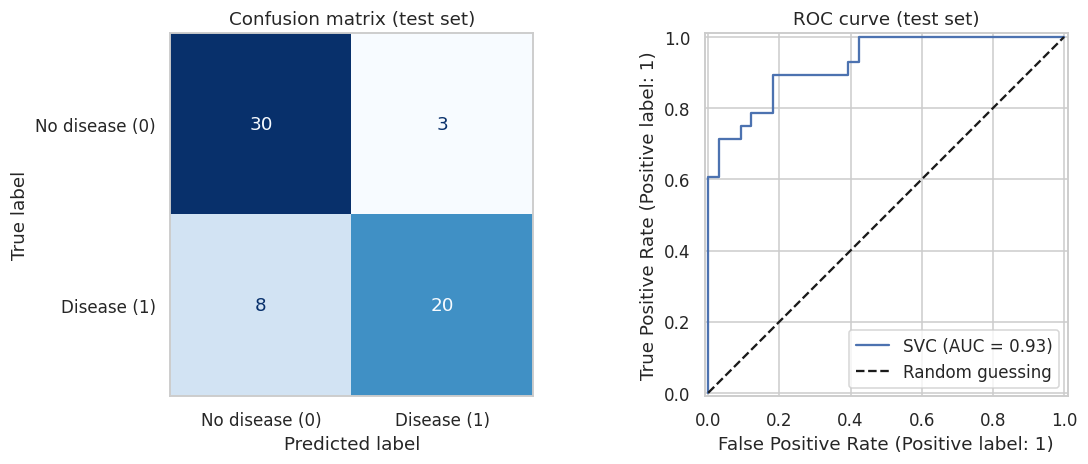

True negatives : 30   (healthy, correctly cleared)
False positives: 3   (healthy, wrongly flagged)
False negatives: 8   (diseased, missed)
True positives : 20   (diseased, correctly flagged)


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No disease (0)", "Disease (1)"],
    cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_score, name="SVC", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[1].set(title="ROC curve (test set)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print(f"True negatives : {tn}   (healthy, correctly cleared)")
print(f"False positives: {fp}   (healthy, wrongly flagged)")
print(f"False negatives: {fn}   (diseased, missed)")
print(f"True positives : {tp}   (diseased, correctly flagged)")

## 7.4 How reliable is this score?

Three numbers are compared: the cross-validated accuracy from training, the training accuracy, and the test accuracy. A test set of only 61 patients is small, so the 95% **Wilson confidence interval** shows the plausible range of the true accuracy (each patient is worth about 1.6 percentage points).

In [24]:
def wilson_interval(successes, n, z=1.96):
    # 95% Wilson score interval for a proportion
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

n_test = len(y_test)
n_correct = int((y_pred == y_test).sum())
ci_low, ci_high = wilson_interval(n_correct, n_test)

print(f"Cross-validated accuracy (training, 5-fold) : {grid.best_score_:.3f}")
print(f"Training accuracy                           : {accuracy_score(y_train, model.predict(X_train)):.3f}")
print(f"Test accuracy                               : {n_correct / n_test:.3f}  ({n_correct} of {n_test} patients)")
print(f"95% confidence interval for test accuracy   : {ci_low:.3f} to {ci_high:.3f}")

Cross-validated accuracy (training, 5-fold) : 0.777
Training accuracy                           : 0.777
Test accuracy                               : 0.820  (50 of 61 patients)
95% confidence interval for test accuracy   : 0.705 to 0.896


The three accuracies are close to one another, so the model is **not overfitted**. If anything, the training accuracy is no higher than the cross-validated accuracy, which means performance is limited by the information in the four inputs rather than by memorisation. The test accuracy is a little higher than the cross-validated one, which is plausible chance variation on only 61 patients. The interval is wide because the test set is small: the honest conclusion is that the true accuracy is somewhere between roughly 70% and 90%, and the cross-validated figure from the larger training set is the steadier estimate.

## 7.5 Error analysis: which test patients were misclassified?

In [25]:
errors = X_test.assign(actual=y_test, predicted=y_pred, decision_score=y_score.round(2))
errors = errors[errors["actual"] != errors["predicted"]].sort_values("decision_score")
print(f"{len(errors)} of {len(y_test)} test patients were misclassified:")
display(errors)

11 of 61 test patients were misclassified:


,cp,thalach,oldpeak,exang,actual,predicted,decision_score
157,4.0,171.0,0.0,0.0,1,0,-0.73
243,1.0,145.0,2.6,0.0,1,0,-0.71
284,4.0,161.0,0.0,0.0,1,0,-0.63
137,2.0,103.0,1.4,0.0,1,0,-0.29
23,3.0,173.0,3.2,0.0,1,0,-0.28
104,3.0,139.0,2.0,0.0,1,0,-0.24
66,3.0,155.0,3.0,0.0,1,0,-0.16
187,2.0,120.0,0.0,1.0,1,0,-0.02
233,2.0,121.0,0.2,1.0,0,1,0.02
271,4.0,138.0,2.3,0.0,0,1,0.15


Most of the errors (8 of 11) are **missed disease cases** (false negatives), and 7 of those 8 patients report no exercise-induced angina, which pushes the model toward "healthy". The 3 false alarms all show a symptom pattern that resembles the disease (asymptomatic chest pain type and/or exercise-induced angina). Eight of the 11 errors have a decision score within about 0.3 of the boundary (0), so they are borderline cases rather than confident mistakes. Four inputs cannot capture everything a cardiologist sees, which is a limitation discussed in Step 11.

---
# Step 8: Save the Trained Model

The fitted pipeline is saved with `pickle`, so it can be loaded later (by the web app) and used for predictions **without training again**. A small `model_info.json` file records the inputs, the valid ranges and the metrics for documentation.

In [26]:
MODEL_PATH = Path("heart_disease_model.pkl")
INFO_PATH = Path("model_info.json")

with open(MODEL_PATH, "wb") as f:
    pickle.dump(model, f)

model_info = {
    "model": "StandardScaler + SVC (scikit-learn Pipeline)",
    "dataset": "UCI Heart Disease, Cleveland Clinic Foundation (303 patients)",
    "input_features": SELECTED_FEATURES,
    "input_ranges": {k: list(v) for k, v in INPUT_RANGES.items()},
    "output": {"name": "target", "0": "no heart disease", "1": "heart disease present"},
    "best_hyperparameters": {k.replace("model__", ""): (v if isinstance(v, str) else float(v))
                             for k, v in grid.best_params_.items()},
    "train_size": int(len(X_train)),
    "test_size": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "cv_accuracy": round(float(grid.best_score_), 4),
    "test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "scikit_learn_version": sklearn.__version__,
}
INFO_PATH.write_text(json.dumps(model_info, indent=2))

print(f"Saved {MODEL_PATH}  ({MODEL_PATH.stat().st_size:,} bytes)")
print(f"Saved {INFO_PATH}  ({INFO_PATH.stat().st_size:,} bytes)")

Saved heart_disease_model.pkl  (10,996 bytes)
Saved model_info.json  (900 bytes)


**Verify the saved model.** The file is loaded back from disk and must give exactly the same predictions as the model in memory.

In [27]:
with open(MODEL_PATH, "rb") as f:
    loaded_model = pickle.load(f)

assert np.array_equal(loaded_model.predict(X_test), model.predict(X_test))
assert np.allclose(loaded_model.decision_function(X_test), model.decision_function(X_test))
print("Loaded model reproduces the in-memory model's predictions exactly.")

Loaded model reproduces the in-memory model's predictions exactly.


---
# Step 9: Make Predictions for New Patients

`predict_heart_disease` is the function the web app mirrors. It:

1. **validates the range of values** of every input and rejects anything outside it,
2. loads the saved model from disk (no re-training),
3. returns the predicted class (0 or 1) and the SVM decision score.

The **decision score** is the signed distance from the SVM decision boundary: positive means class 1 (disease), negative means class 0, and a larger magnitude means the patient lies further from the boundary. It is *not* a probability.

In [28]:
def predict_heart_disease(cp, thalach, oldpeak, exang, model_path=MODEL_PATH):
    values = {"cp": cp, "thalach": thalach, "oldpeak": oldpeak, "exang": exang}

    # 1) validate the range of values
    for name, value in values.items():
        low, high = INPUT_RANGES[name]
        if not (low <= value <= high):
            raise ValueError(f"{name} = {value} is outside the valid range {low} to {high}")
    if cp not in (1, 2, 3, 4):
        raise ValueError("cp must be one of 1, 2, 3, 4")
    if exang not in (0, 1):
        raise ValueError("exang must be 0 or 1")

    # 2) load the saved model (no re-training)
    with open(model_path, "rb") as f:
        saved_model = pickle.load(f)

    # 3) predict
    new_patient = pd.DataFrame([values], columns=SELECTED_FEATURES).astype(float)
    prediction = int(saved_model.predict(new_patient)[0])
    score = float(saved_model.decision_function(new_patient)[0])
    return {"prediction": prediction,
            "meaning": "Heart disease likely" if prediction == 1 else "No heart disease likely",
            "decision_score": round(score, 3)}


example_patients = {
    "Patient A": dict(cp=2, thalach=170, oldpeak=0.0, exang=0),
    "Patient B": dict(cp=4, thalach=110, oldpeak=2.5, exang=1),
    "Patient C": dict(cp=3, thalach=140, oldpeak=1.0, exang=0),
}

rows = []
for name, inputs in example_patients.items():
    rows.append({"Patient": name, **inputs, **predict_heart_disease(**inputs)})
display(pd.DataFrame(rows))

,Patient,cp,thalach,oldpeak,exang,prediction,meaning,decision_score
0,Patient A,2,170,0.0,0,0,No heart disease likely,-1.272
1,Patient B,4,110,2.5,1,1,Heart disease likely,1.240
2,Patient C,3,140,1.0,0,0,No heart disease likely,-0.491


**Range-of-values check.** An input outside the valid range is rejected instead of being passed to the model:

In [29]:
invalid_inputs = [
    dict(cp=4, thalach=250, oldpeak=1.0, exang=1),   # heart rate far above the observed range
    dict(cp=7, thalach=150, oldpeak=1.0, exang=0),   # chest pain code that does not exist
    dict(cp=3, thalach=150, oldpeak=-1.0, exang=0),  # negative ST depression
]
for inputs in invalid_inputs:
    try:
        predict_heart_disease(**inputs)
    except ValueError as err:
        print("Rejected ->", err)

Rejected -> thalach = 250 is outside the valid range 71 to 202
Rejected -> cp = 7 is outside the valid range 1 to 4
Rejected -> oldpeak = -1.0 is outside the valid range 0.0 to 6.2


---
# Step 10: Deploy the Model to the Cloud

The model is served by a **Streamlit** web app (`app.py`) hosted on **Streamlit Community Cloud**, the same hosting used for the instructor's Titanic live demo. The app loads `heart_disease_model.pkl`, shows one input control per attribute, limited to the valid ranges from Step 4.5, and displays the prediction.

**Deployment steps**

1. Upload the project folder to a new **public GitHub repository**, with `app.py` and `requirements.txt` at the top level next to `heart_disease_model.pkl`, `processed_cleveland.csv` and `model_info.json`.
2. Sign in at [share.streamlit.io](https://share.streamlit.io) with GitHub and click **Create app**.
3. Choose the repository, the branch (`main`) and the main file path `app.py`. Under *Advanced settings* select **Python 3.12**.
4. Click **Deploy**. After a few minutes the app is live at `https://<app-name>.streamlit.app/`.
5. Copy that URL into the **first cell of this notebook**, then re-export the PDF report.
6. Test the live app with Patients A, B and C from Step 9. The results must match the notebook.

To test locally first: `pip install -r requirements.txt` and then `streamlit run app.py`.

**Files used for deployment**

In [30]:
deploy_files = ["app.py", "heart_disease_model.pkl", "processed_cleveland.csv",
                "model_info.json", "requirements.txt", "requirements-notebook.txt", "README.md"]
for name in deploy_files:
    p = Path(name)
    status = "found" if p.exists() else "MISSING"
    size = f"{p.stat().st_size:>9,d} bytes" if p.exists() else ""
    print(f"{name:28s} {status:8s} {size}")

app.py                       found        7,667 bytes
heart_disease_model.pkl      found       10,996 bytes
processed_cleveland.csv      found       18,538 bytes
model_info.json              found          900 bytes
requirements.txt             found           59 bytes
requirements-notebook.txt    found           58 bytes
README.md                    found        4,079 bytes


**Source code of the deployed web app (`app.py`)**

In [31]:
print(Path("app.py").read_text())

"""Heart Disease Prediction System: Streamlit web app (Assignment 2, Task 2).

Course : AIC354 Machine Learning Fundamentals, COMSATS University Islamabad, Lahore Campus
Student: Haziq Mahmood (FA24-BSE-049)

The app loads the trained scikit-learn pipeline (StandardScaler + SVC) that was saved by
Heart_Disease_Prediction.ipynb and predicts, from 4 inputs, whether a patient has heart
disease (output 1) or not (output 0).
"""
import csv
import json
import pickle
from datetime import datetime
from pathlib import Path

import pandas as pd
import streamlit as st

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "heart_disease_model.pkl"
DATA_PATH = BASE_DIR / "processed_cleveland.csv"
INFO_PATH = BASE_DIR / "model_info.json"
FEEDBACK_PATH = BASE_DIR / "feedback.csv"

# The 4 input attributes, in the order the model was trained with
FEATURES = ["cp", "thalach", "oldpeak", "exang"]

# Range of values of each input (identical to Step 4.5 of the notebook)
CP_LABELS = {1: "Typi

---
# Step 11: Collect Feedback, Evaluate, and Improve

## 11.1 Results summary

In [32]:
summary = pd.DataFrame({
    "Item": ["Input attributes", "Output attribute", "Model", "Best hyperparameters",
             "Cross-validated accuracy (training)", "Test accuracy", "Test recall (sensitivity)",
             "Test ROC-AUC", "Majority-class baseline accuracy"],
    "Value": [", ".join(SELECTED_FEATURES), "target (0 = no disease, 1 = disease)",
              "StandardScaler + SVC", str(model_info["best_hyperparameters"]),
              f"{grid.best_score_:.3f}", f"{metrics['Accuracy']:.3f}",
              f"{metrics['Recall (sensitivity)']:.3f}", f"{metrics['ROC-AUC']:.3f}",
              f"{baseline_acc:.3f}"],
})
display(summary)

,Item,Value
0,Input attributes,"cp, thalach, oldpeak, exang"
1,Output attribute,"target (0 = no disease, 1 = disease)"
2,Model,StandardScaler + SVC
3,Best hyperparameters,"{'C': 0.5, 'gamma': 0.01, 'kernel': 'rbf'}"
4,Cross-validated accuracy (training),0.777
5,Test accuracy,0.820
6,Test recall (sensitivity),0.714
7,Test ROC-AUC,0.925
8,Majority-class baseline accuracy,0.541


## 11.2 What does the 4-attribute constraint cost?

For context, the same untuned SVC is trained on **all 13 attributes** (with missing values filled by the training median inside the pipeline) and compared with the 4-attribute version, using the same repeated cross-validation on the training set.

In [33]:
all_features_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC()),
])
scores_13 = cross_val_score(all_features_pipeline, train_df[FEATURE_CANDIDATES], train_df["target"],
                            cv=CV_REPEATED, scoring="accuracy")
scores_4 = cross_val_score(base_pipeline, X_train, y_train, cv=CV_REPEATED, scoring="accuracy")

display(pd.DataFrame({
    "Inputs": ["4 selected attributes", "all 13 attributes"],
    "CV accuracy (mean)": [scores_4.mean(), scores_13.mean()],
    "Std": [scores_4.std(), scores_13.std()],
}).round(3))

,Inputs,CV accuracy (mean),Std
0,4 selected attributes,0.761,0.049
1,all 13 attributes,0.819,0.045


Using all 13 attributes would raise the cross-validated accuracy by several percentage points. That is the **price of the 4-input constraint** in this assignment; it is accepted here in exchange for a model that a user can run from four easy-to-enter values.

## 11.3 Limitations

- **Small, old, single-hospital data.** 303 patients from one clinic in the 1980s. The model may not generalise to other populations, and 68% of the patients are male.
- **Small test set.** 61 patients give a wide confidence interval (Step 7.4), so the test accuracy should not be over-interpreted.
- **Only 4 inputs.** Important information (for example the number of blocked vessels and the thallium test result) is not available to the model.
- **Not a diagnostic tool.** The system is an educational exercise. It must not be used to diagnose or exclude heart disease; a medical professional must always be consulted.

## 11.4 Possible improvements

- Use more attributes, or add the other three UCI hospital databases, to train on more data.
- Tune the decision threshold to favour **recall**, because a missed patient is costlier than a false alarm.
- Add probability calibration (for example `CalibratedClassifierCV`) so the app can show a reliable risk percentage.
- Validate on an external dataset collected at a different hospital.

## 11.5 Feedback loop in the deployed app

The web app includes a short feedback form (was the result useful, plus an optional comment). Feedback is the final stage of the ML cycle: it shows how real users experience the system and which improvements should be made next. On the free Streamlit Community Cloud, files written by the app are not permanent, so for a production system the feedback would be stored in a database or a cloud spreadsheet.

---
**End of notebook.** Files produced: `heart_disease_model.pkl` (trained model), `model_info.json` (model documentation), and the deployed web app.